# Punto 1A · Modelo de difusión (DDPM) entrenado con **MNIST**

**Universidad Autónoma de Occidente** · Inteligencia Artificial Generativa · Ingeniería de Datos e IA
Profesores: Jesús Alfonso López – José Luis Paniagua

En este notebook partimos del código de ejemplo de la clase (DDPM sobre Fashion MNIST) y hacemos tres cosas:

1. **Cambiamos el conjunto de datos** por el MNIST tradicional (dígitos escritos a mano, 28×28, escala de grises).
2. **Entrenamos** el mismo modelo de difusión tipo UNet para que aprenda a quitar ruido de imágenes de dígitos.
3. **Evaluamos la calidad** de las imágenes generadas con métricas cuantitativas: FID, KID, *Inception/Classifier Score*, confianza de un clasificador y cobertura de clases.

Como MNIST tiene exactamente la misma forma que Fashion MNIST (28×28×1), la arquitectura del profe funciona sin cambios: lo único que cambia es la fuente de datos. Eso nos permite comparar de forma limpia.

> ⚙️ Antes de correr: **Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)**.

## 0. Configuración del entorno
Mantenemos la misma configuración del notebook original para garantizar compatibilidad entre Python, TensorFlow y Keras (en Colab se usa *Keras legacy* `tf_keras`, que permite mezclar operaciones de TensorFlow dentro del modelo funcional).

In [1]:
import sys, os
assert sys.version_info >= (3, 7)

IS_COLAB = "google.colab" in sys.modules
if IS_COLAB:
    # Debe ir ANTES de importar tensorflow: fuerza Keras 2 (tf_keras)
    os.environ["TF_USE_LEGACY_KERAS"] = "1"
    import tf_keras

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from packaging import version
from scipy import linalg

assert version.parse(tf.__version__) >= version.parse("2.8.0")
print("TensorFlow:", tf.__version__)

if not tf.config.list_physical_devices("GPU"):
    print("⚠️ No se detectó GPU. El entrenamiento y sobre todo la generación serán MUY lentos.")
else:
    print("GPU detectada:", tf.config.list_physical_devices("GPU")[0])

TensorFlow: 2.20.0
⚠️ No se detectó GPU. El entrenamiento y sobre todo la generación serán MUY lentos.


## 1. Carga de MNIST
Aquí está el cambio principal respecto al notebook original: `fashion_mnist` → `mnist`. Normalizamos a [0, 1] (luego `prepare_batch` lo lleva a [–1, 1]) y separamos 5.000 imágenes para validación, igual que en el ejemplo.

In [2]:
mnist = tf.keras.datasets.mnist.load_data()          # <-- ÚNICO cambio de datos
(X_train_full, y_train_full), (X_test, y_test) = mnist
X_train_full = X_train_full.astype(np.float32) / 255
X_test = X_test.astype(np.float32) / 255
X_train, X_valid = X_train_full[:-5000], X_train_full[-5000:]
y_train, y_valid = y_train_full[:-5000], y_train_full[-5000:]

print("Entrenamiento:", X_train.shape, "| Validación:", X_valid.shape, "| Prueba:", X_test.shape)

Entrenamiento: (55000, 28, 28) | Validación: (5000, 28, 28) | Prueba: (10000, 28, 28)


Algunos dígitos reales de MNIST:


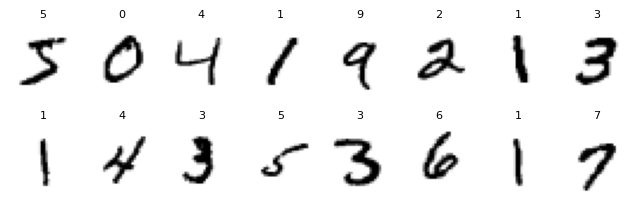

In [3]:
def plot_multiple_images(images, n_cols=None, titles=None):
    # Muestra una cuadrícula de imágenes. Acepta (N, H, W) o (N, H, W, 1)
    images = np.asarray(images)
    n_cols = n_cols or len(images)
    n_rows = (len(images) - 1) // n_cols + 1
    if images.shape[-1] == 1:
        images = images.squeeze(axis=-1)
    plt.figure(figsize=(n_cols, n_rows * (1.2 if titles is not None else 1)))
    for index, image in enumerate(images):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(image, cmap="binary")
        if titles is not None:
            plt.title(titles[index], fontsize=8)
        plt.axis("off")

print("Algunos dígitos reales de MNIST:")
plot_multiple_images(X_train[:16], 8, titles=[str(y) for y in y_train[:16]])
plt.show()

## 2. Proceso de difusión directo (*forward*)

En cada paso $t$ se añade ruido gaussiano con varianza $\beta_t$. Usamos la programación coseno del artículo *Improved DDPM* con $T = 4000$, exactamente como en el ejemplo. Gracias a la ecuación (4) del artículo DDPM podemos saltar directamente de la imagen limpia $x_0$ a la imagen ruidosa $x_t$:

$$x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon,\qquad \varepsilon\sim\mathcal N(0, I)$$

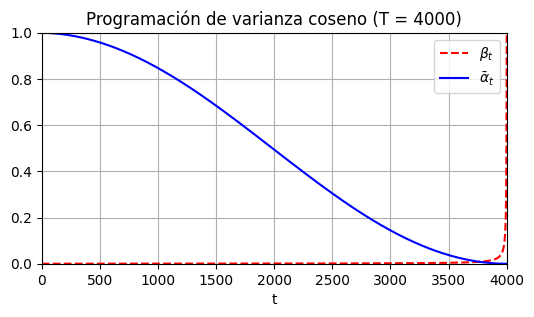

In [4]:
def variance_schedule(T, s=0.008, max_beta=0.999):
    # Programación coseno (Improved DDPM): ᾱ_t baja suavemente de 1 a 0
    t = np.arange(T + 1)
    f = np.cos((t / T + s) / (1 + s) * np.pi / 2) ** 2
    alpha = np.clip(f[1:] / f[:-1], 1 - max_beta, 1)
    alpha = np.append(1, alpha).astype(np.float32)  # α₀ = 1
    beta = 1 - alpha
    alpha_cumprod = np.cumprod(alpha)
    return alpha, alpha_cumprod, beta  # αₜ, ᾱₜ, βₜ para t = 0..T

np.random.seed(42)
T = 4000
alpha, alpha_cumprod, beta = variance_schedule(T)

plt.figure(figsize=(6, 3))
plt.plot(beta, "r--", label=r"$\beta_t$")
plt.plot(alpha_cumprod, "b", label=r"$\bar{\alpha}_t$")
plt.axis([0, T, 0, 1]); plt.grid(True); plt.xlabel("t"); plt.legend()
plt.title("Programación de varianza coseno (T = 4000)")
plt.show()

In [5]:
def prepare_batch(X):
    # Toma un lote de imágenes limpias y devuelve (entradas, objetivo):
    #   entradas = imagen ruidosa x_t y el paso t (aleatorio entre 1 y T)
    #   objetivo = el ruido ε que se añadió (es lo que la red debe predecir)
    X = tf.cast(X[..., tf.newaxis], tf.float32) * 2 - 1  # escala a [-1, 1]
    X_shape = tf.shape(X)
    t = tf.random.uniform([X_shape[0]], minval=1, maxval=T + 1, dtype=tf.int32)
    alpha_cm = tf.gather(alpha_cumprod, t)
    alpha_cm = tf.reshape(alpha_cm, [X_shape[0]] + [1] * (len(X.shape) - 1))
    noise = tf.random.normal(X_shape)
    return {
        "X_noisy": alpha_cm ** 0.5 * X + (1 - alpha_cm) ** 0.5 * noise,
        "time": t,
    }, noise

def prepare_dataset(X, batch_size=32, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(X)
    if shuffle:
        ds = ds.shuffle(10_000)
    return ds.batch(batch_size).map(prepare_batch, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

tf.random.set_seed(43)
BATCH_SIZE = 32
train_set = prepare_dataset(X_train, batch_size=BATCH_SIZE, shuffle=True)
valid_set = prepare_dataset(X_valid, batch_size=BATCH_SIZE)

Comprobación rápida: tomamos un lote, miramos las imágenes ruidosas, el ruido que hay que predecir y reconstruimos la original restando el ruido escalado. Si la reconstrucción se ve perfecta, el *pipeline* de datos está bien.

Imágenes originales reconstruidas


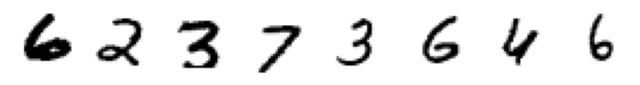

Pasos de tiempo: [3405  312 3441 1991 2443 1657 3308 1151]
Imágenes ruidosas


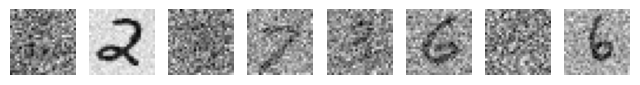

Ruido a predecir


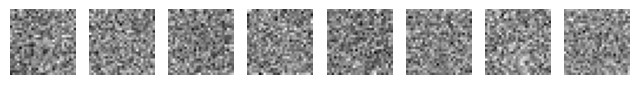

In [6]:
def subtract_noise(X_noisy, time, noise):
    X_shape = tf.shape(X_noisy)
    alpha_cm = tf.gather(alpha_cumprod, time)
    alpha_cm = tf.reshape(alpha_cm, [X_shape[0]] + [1] * (len(X_noisy.shape) - 1))
    return (X_noisy - (1 - alpha_cm) ** 0.5 * noise) / alpha_cm ** 0.5

X_dict, Y_noise = list(train_set.take(1))[0]
X_original = subtract_noise(X_dict["X_noisy"], X_dict["time"], Y_noise)

print("Imágenes originales reconstruidas"); plot_multiple_images(X_original[:8].numpy()); plt.show()
print("Pasos de tiempo:", X_dict["time"].numpy()[:8])
print("Imágenes ruidosas"); plot_multiple_images(X_dict["X_noisy"][:8].numpy()); plt.show()
print("Ruido a predecir"); plot_multiple_images(Y_noise[:8].numpy()); plt.show()

Y para ver el proceso directo de forma más intuitiva, tomamos un mismo dígito y lo vamos ensuciando a distintos $t$:

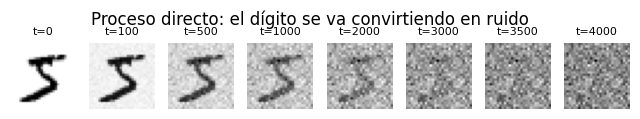

In [7]:
x0 = X_train[0][np.newaxis, ..., np.newaxis] * 2 - 1
steps_to_show = [int(T * f) for f in (0, 0.025, 0.125, 0.25, 0.5, 0.75, 0.875, 1.0)]
eps = np.random.randn(*x0.shape).astype(np.float32)
noisy = [np.sqrt(alpha_cumprod[t]) * x0[0] + np.sqrt(1 - alpha_cumprod[t]) * eps[0] for t in steps_to_show]
plot_multiple_images(np.array(noisy), 8, titles=[f"t={t}" for t in steps_to_show])
plt.suptitle("Proceso directo: el dígito se va convirtiendo en ruido", y=1.05)
plt.show()

## 3. El modelo: UNet con codificación temporal

Usamos **la misma arquitectura del ejemplo**. La red recibe la imagen ruidosa y el paso $t$; el tiempo se codifica con senos y cosenos (como en *Attention is all you need*), pasa por una capa `Dense` y se suma a cada píxel en cada bloque. La UNet baja la resolución 32→16→8→4 y la vuelve a subir, con conexiones de salto entre ambas mitades.

No hace falta tocarla porque MNIST también es 28×28×1 (la red rellena a 34×34 con `ZeroPadding2D`, trabaja en 32×32 y al final recorta a 28×28).

In [8]:
embed_size = 64

class TimeEncoding(tf.keras.layers.Layer):
    # Codificación sinusoidal del paso t (tabla precalculada de T+1 filas)
    def __init__(self, T, embed_size, dtype=tf.float32, **kwargs):
        super().__init__(dtype=dtype, **kwargs)
        assert embed_size % 2 == 0, "embed_size debe ser par"
        p, i = np.meshgrid(np.arange(T + 1), 2 * np.arange(embed_size // 2))
        t_emb = np.empty((T + 1, embed_size))
        t_emb[:, ::2] = np.sin(p / 10_000 ** (i / embed_size)).T
        t_emb[:, 1::2] = np.cos(p / 10_000 ** (i / embed_size)).T
        self.time_encodings = tf.constant(t_emb.astype(self.dtype))

    def call(self, inputs):
        return tf.gather(self.time_encodings, inputs)


def build_diffusion_model():
    X_noisy = tf.keras.layers.Input(shape=[28, 28, 1], name="X_noisy")
    time_input = tf.keras.layers.Input(shape=[], dtype=tf.int32, name="time")
    time_enc = TimeEncoding(T, embed_size)(time_input)

    dim = 16
    Z = tf.keras.layers.ZeroPadding2D((3, 3))(X_noisy)       # 28 -> 34
    Z = tf.keras.layers.Conv2D(dim, 3)(Z)                     # 34 -> 32
    Z = tf.keras.layers.BatchNormalization()(Z)
    Z = tf.keras.layers.Activation("relu")(Z)

    time = tf.keras.layers.Dense(dim)(time_enc)               # adapta la codificación temporal
    Z = time[:, tf.newaxis, tf.newaxis, :] + Z                # suma el tiempo a cada píxel

    skip = Z
    cross_skips = []  # conexiones de salto entre la parte de bajada y la de subida

    # ----- Codificador (bajada): 32 -> 16 -> 8 -> 4 -----
    for dim in (32, 64, 128):
        Z = tf.keras.layers.Activation("relu")(Z)
        Z = tf.keras.layers.SeparableConv2D(dim, 3, padding="same")(Z)
        Z = tf.keras.layers.BatchNormalization()(Z)
        Z = tf.keras.layers.Activation("relu")(Z)
        Z = tf.keras.layers.SeparableConv2D(dim, 3, padding="same")(Z)
        Z = tf.keras.layers.BatchNormalization()(Z)

        cross_skips.append(Z)
        Z = tf.keras.layers.MaxPooling2D(3, strides=2, padding="same")(Z)
        skip_link = tf.keras.layers.Conv2D(dim, 1, strides=2, padding="same")(skip)
        Z = tf.keras.layers.add([Z, skip_link])               # conexión residual

        time = tf.keras.layers.Dense(dim)(time_enc)
        Z = time[:, tf.newaxis, tf.newaxis, :] + Z
        skip = Z

    # ----- Decodificador (subida): 4 -> 8 -> 16 -> 32 -----
    for dim in (64, 32, 16):
        Z = tf.keras.layers.Activation("relu")(Z)
        Z = tf.keras.layers.Conv2DTranspose(dim, 3, padding="same")(Z)
        Z = tf.keras.layers.BatchNormalization()(Z)
        Z = tf.keras.layers.Activation("relu")(Z)
        Z = tf.keras.layers.Conv2DTranspose(dim, 3, padding="same")(Z)
        Z = tf.keras.layers.BatchNormalization()(Z)

        Z = tf.keras.layers.UpSampling2D(2)(Z)
        skip_link = tf.keras.layers.UpSampling2D(2)(skip)
        skip_link = tf.keras.layers.Conv2D(dim, 1, padding="same")(skip_link)
        Z = tf.keras.layers.add([Z, skip_link])

        time = tf.keras.layers.Dense(dim)(time_enc)
        Z = time[:, tf.newaxis, tf.newaxis, :] + Z
        Z = tf.keras.layers.concatenate([Z, cross_skips.pop()], axis=-1)  # salto cruzado UNet
        skip = Z

    outputs = tf.keras.layers.Conv2D(1, 3, padding="same")(Z)[:, 2:-2, 2:-2]  # recorta 32 -> 28
    return tf.keras.Model(inputs=[X_noisy, time_input], outputs=[outputs])

tf.random.set_seed(42)
model = build_diffusion_model()
print(f"Parámetros del modelo: {model.count_params():,}")


Parámetros del modelo: 280,369


## 4. Entrenamiento
La red aprende a predecir el ruido $\varepsilon$ a partir de $(x_t, t)$. Usamos pérdida Huber y Nadam como en el ejemplo. Subimos las épocas a 20 porque MNIST se beneficia de algo más de entrenamiento (cada época tarda ~45 s en una T4); guardamos solo los mejores pesos según la pérdida de validación.

In [9]:
EPOCHS = 20

model.compile(loss=tf.keras.losses.Huber(), optimizer=tf.keras.optimizers.Nadam())

checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    "mnist_diffusion_best.weights.h5", save_best_only=True, save_weights_only=True)
reduce_lr_cb = tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3, verbose=1)

t0 = time.time()
history = model.fit(train_set, validation_data=valid_set, epochs=EPOCHS,
                    callbacks=[checkpoint_cb, reduce_lr_cb])
print(f"Tiempo de entrenamiento: {(time.time() - t0) / 60:.1f} min")

model.load_weights("mnist_diffusion_best.weights.h5")   # nos quedamos con la mejor época

Epoch 1/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 400s 217ms/step - loss: 0.0826 - val_loss: 0.0475 - learning_rate: 0.0010
Epoch 2/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 538s 308ms/step - loss: 0.0382 - val_loss: 0.0369 - learning_rate: 0.0010
Epoch 3/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 764s 425ms/step - loss: 0.0321 - val_loss: 0.0335 - learning_rate: 0.0010
Epoch 4/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 119s 69ms/step - loss: 0.0297 - val_loss: 0.0289 - learning_rate: 0.0010
Epoch 5/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 126s 73ms/step - loss: 0.0280 - val_loss: 0.0290 - learning_rate: 0.0010
Epoch 6/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 242s 132ms/step - loss: 0.0269 - val_loss: 0.0291 - learning_rate: 0.0010
Epoch 7/20
1718/1719 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - loss: 0.0262
Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 163s 95ms/step - loss: 0.0260 - val_loss: 0.0288 - learning_rate: 0.0010
Epoch 8/20
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 106s 62ms/step

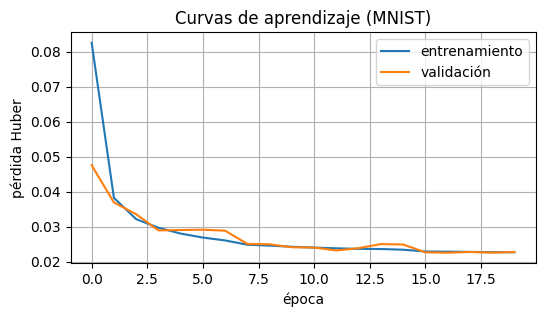

In [10]:
plt.figure(figsize=(6, 3))
plt.plot(history.history["loss"], label="entrenamiento")
plt.plot(history.history["val_loss"], label="validación")
plt.xlabel("época"); plt.ylabel("pérdida Huber"); plt.grid(True); plt.legend()
plt.title("Curvas de aprendizaje (MNIST)")
plt.show()

## 5. Generación de imágenes (proceso inverso)

Partimos de ruido puro $x_T\sim\mathcal N(0,I)$ y aplicamos el paso 4 del Algoritmo 2 del artículo DDPM, desde $t=T-1$ hasta $t=1$ (no desde $T$: con la programación coseno $\alpha_T\approx0.001$ y ese primer paso amplificaría la imagen ≈ 32 veces):

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\left(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\varepsilon_\theta(x_t,t)\right) + \sqrt{\beta_t}\,z$$

**Mejora respecto al ejemplo:** el paso de *denoising* está envuelto en `@tf.function`, así TensorFlow lo compila a grafo una sola vez y las 4.000 llamadas a la red son mucho más rápidas. Eso es lo que nos permite generar suficientes imágenes (1.000) para calcular las métricas de forma confiable.

lote 1 | t =  500 
32 imágenes generadas en 72.9 s


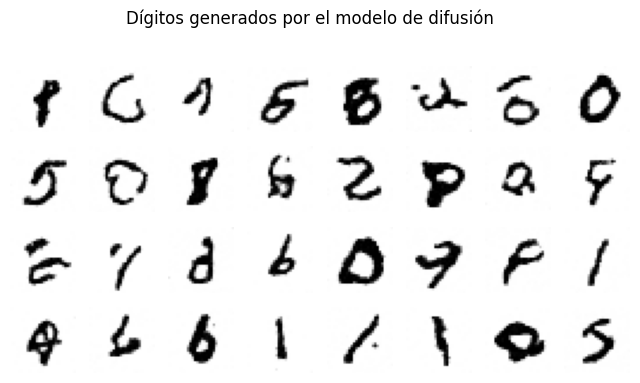

In [11]:
alpha_tf = tf.constant(alpha)
beta_tf = tf.constant(beta)
alpha_cumprod_tf = tf.constant(alpha_cumprod)

@tf.function
def denoise_step(X, t):
    # Un paso del proceso inverso DDPM: x_t -> x_{t-1}
    batch = tf.shape(X)[0]
    t_vec = tf.fill([batch], t)
    eps_pred = model({"X_noisy": X, "time": t_vec}, training=False)
    a_t = tf.gather(alpha_tf, t)
    b_t = tf.gather(beta_tf, t)
    ab_t = tf.gather(alpha_cumprod_tf, t)
    mean = (X - b_t / tf.sqrt(1 - ab_t) * eps_pred) / tf.sqrt(a_t)
    z = tf.random.normal(tf.shape(X)) * tf.cast(t > 1, tf.float32)  # sin ruido en el último paso
    return mean + tf.sqrt(b_t) * z

def generate(n_images=32, batch_size=500, snapshot_steps=None, verbose=True):
    # Genera n_images; si se pasa snapshot_steps guarda x_t en esos pasos (para visualizar)
    outputs, snapshots = [], {}
    for start in range(0, n_images, batch_size):
        bs = min(batch_size, n_images - start)
        X = tf.random.normal([bs, 28, 28, 1])
        # Empezamos en T-1 (como el notebook de clase): en t = T la programación coseno
        # tiene α_T ≈ 0.001 y el paso multiplicaría la imagen por 1/√α ≈ 31.6, lo que
        # satura algunas muestras (salen cuadros negros).
        for t in range(T - 1, 0, -1):
            X = denoise_step(X, tf.constant(t, tf.int32))
            if snapshot_steps is not None and start == 0 and (t - 1) in snapshot_steps:
                snapshots[t - 1] = X.numpy()
            if verbose and t % max(T // 8, 1) == 0:
                print(f"\rlote {start // batch_size + 1} | t = {t:4d}", end=" ")
        outputs.append(tf.clip_by_value(X, -1, 1).numpy())
    if verbose:
        print()
    X_gen = np.concatenate(outputs)
    return (X_gen, snapshots) if snapshot_steps is not None else X_gen

tf.random.set_seed(42)
t0 = time.time()
snap_steps = [T - 2] + [int(T * f) for f in (0.75, 0.5, 0.375, 0.25, 0.15, 0.075, 0.025, 0.0075)] + [0]
X_gen_demo, snaps = generate(32, batch_size=32, snapshot_steps=snap_steps)
print(f"32 imágenes generadas en {time.time() - t0:.1f} s")

plot_multiple_images(X_gen_demo, 8)
plt.suptitle("Dígitos generados por el modelo de difusión", y=1.02)
plt.show()

### Visualización del proceso inverso
Cada fila es una imagen distinta; de izquierda a derecha vemos cómo el ruido se va organizando en un dígito. Nótese que la forma global aparece relativamente tarde (por la programación coseno, la mayor parte de la estructura se decide en la segunda mitad del proceso).

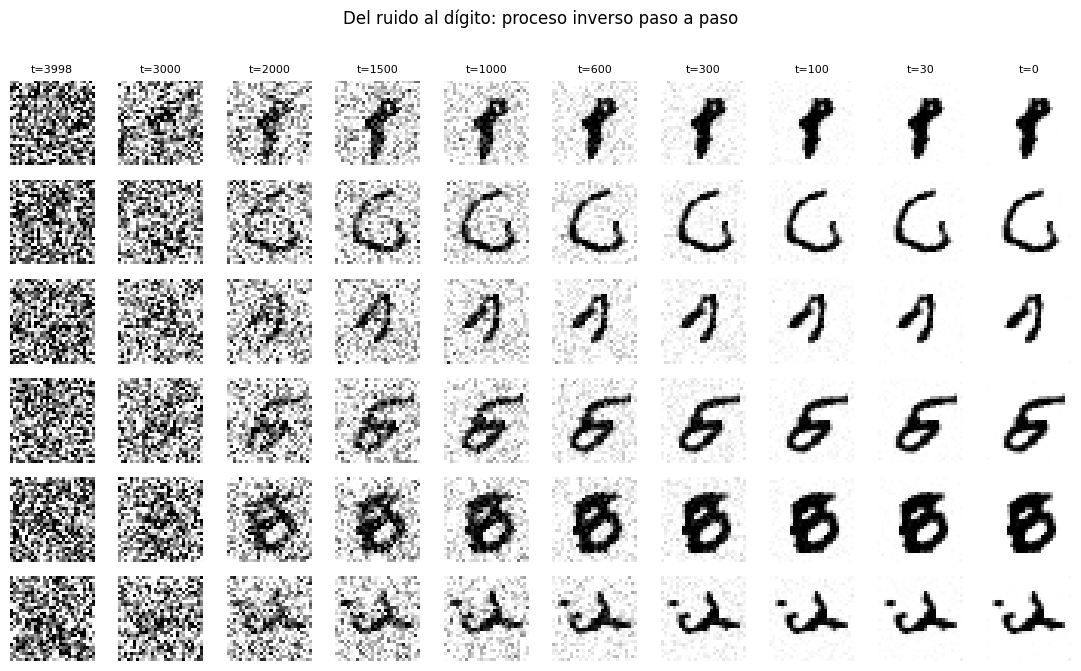

In [12]:
order = sorted(snaps.keys(), reverse=True)
n_show = 6
fig, axes = plt.subplots(n_show, len(order), figsize=(len(order) * 1.1, n_show * 1.1))
for r in range(n_show):
    for c, t in enumerate(order):
        axes[r, c].imshow(np.clip(snaps[t][r, ..., 0], -1, 1), cmap="binary")
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(f"t={t}", fontsize=8)
plt.suptitle("Del ruido al dígito: proceso inverso paso a paso", y=1.01)
plt.tight_layout(); plt.show()

## 6. Evaluación cuantitativa de la calidad

Mirar las imágenes no es suficiente; necesitamos números. Las métricas estándar para modelos generativos de imágenes son:

| Métrica | Qué mide | Mejor si… |
|---|---|---|
| **FID** (*Fréchet Inception Distance*) | Distancia entre la distribución de características de imágenes reales y generadas (media y covarianza). Captura calidad **y** diversidad. | ↓ más bajo |
| **KID** (*Kernel Inception Distance*) | Parecido al FID pero con un estimador insesgado (MMD con kernel polinomial). Más confiable con pocas muestras. | ↓ más bajo |
| **IS / Classifier Score** | $\exp(\mathbb E_x[KL(p(y\mid x)\,\|\,p(y))])$: alto si cada imagen se clasifica con seguridad (nitidez) y las clases están balanceadas (diversidad). Máximo teórico = 10 en MNIST. | ↑ más alto |
| **Confianza media** | Probabilidad máxima promedio del clasificador: ¿la imagen parece claramente un dígito? | ↑ más alto |
| **Cobertura de clases** | Histograma de clases predichas y su entropía: detecta *mode collapse* (que el modelo solo genere algunos dígitos). | entropía ≈ ln 10 = 2.30 |

**Detalle importante:** el FID “oficial” usa InceptionV3 entrenada en ImageNet, pero para dígitos en escala de grises de 28×28 eso no tiene mucho sentido. La práctica habitual en MNIST es usar como extractor de características **un clasificador entrenado en MNIST** (las activaciones de su penúltima capa). Eso es lo que hacemos aquí. Por eso los valores no son comparables con FID publicados en ImageNet/CIFAR, pero sí entre modelos evaluados con el mismo extractor, y los acompañamos de **líneas base** (real vs real y ruido vs real) para interpretarlos.

### 6.1 Clasificador de referencia para MNIST

In [13]:
def build_classifier():
    inp = tf.keras.layers.Input(shape=[28, 28, 1])
    x = tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu")(inp)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.Dropout(0.25)(x)
    x = tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.Flatten()(x)
    x = tf.keras.layers.Dense(128, activation="relu", name="features")(x)   # <- características para FID/KID
    x = tf.keras.layers.Dropout(0.5)(x)
    out = tf.keras.layers.Dense(10, activation="softmax")(x)
    return tf.keras.Model(inp, out)

# El clasificador recibe imágenes en [-1, 1], el mismo rango que produce el generador
to_pm1 = lambda X: (X[..., np.newaxis] * 2 - 1).astype(np.float32)

clf = build_classifier()
clf.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
clf.fit(to_pm1(X_train), y_train, validation_data=(to_pm1(X_valid), y_valid),
        epochs=5, batch_size=128, verbose=2)
_, test_acc = clf.evaluate(to_pm1(X_test), y_test, verbose=0)
print(f"Exactitud del clasificador en prueba: {test_acc:.4f}")

feature_extractor = tf.keras.Model(clf.input, clf.get_layer("features").output)

Epoch 1/5
430/430 - 37s - 87ms/step - accuracy: 0.7394 - loss: 0.7182 - val_accuracy: 0.9820 - val_loss: 0.1203
Epoch 2/5
430/430 - 35s - 82ms/step - accuracy: 0.8609 - loss: 0.3718 - val_accuracy: 0.9862 - val_loss: 0.0467
Epoch 3/5
430/430 - 34s - 80ms/step - accuracy: 0.8839 - loss: 0.3098 - val_accuracy: 0.9886 - val_loss: 0.0412
Epoch 4/5
430/430 - 35s - 81ms/step - accuracy: 0.9037 - loss: 0.2502 - val_accuracy: 0.9890 - val_loss: 0.0409
Epoch 5/5
430/430 - 35s - 81ms/step - accuracy: 0.9223 - loss: 0.2109 - val_accuracy: 0.9886 - val_loss: 0.0415
Exactitud del clasificador en prueba: 0.9888


### 6.2 Funciones de las métricas

In [14]:
def get_feats_probs(X, batch_size=500):
    feats = feature_extractor.predict(X, batch_size=batch_size, verbose=0).astype(np.float64)
    probs = clf.predict(X, batch_size=batch_size, verbose=0).astype(np.float64)
    return feats, probs

def fid(f1, f2):
    # FID = ||μ1-μ2||² + Tr(Σ1 + Σ2 - 2(Σ1Σ2)^½)
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    covmean = linalg.sqrtm(s1.dot(s2))
    if isinstance(covmean, tuple):          # compatibilidad entre versiones de SciPy
        covmean = covmean[0]
    if not np.isfinite(covmean).all():      # estabilización numérica si la matriz es casi singular
        off = np.eye(s1.shape[0]) * 1e-6
        covmean = linalg.sqrtm((s1 + off).dot(s2 + off))
        covmean = covmean[0] if isinstance(covmean, tuple) else covmean
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean))

def kid(f1, f2, n_subsets=50, subset_size=500, seed=0):
    # KID: MMD² insesgado con kernel polinomial k(x,y) = (x·y/d + 1)³; promedio sobre subconjuntos
    rng = np.random.default_rng(seed)
    d = f1.shape[1]
    m = min(subset_size, len(f1), len(f2))
    vals = []
    for _ in range(n_subsets):
        x = f1[rng.choice(len(f1), m, replace=False)]
        y = f2[rng.choice(len(f2), m, replace=False)]
        kxx = (x @ x.T / d + 1) ** 3
        kyy = (y @ y.T / d + 1) ** 3
        kxy = (x @ y.T / d + 1) ** 3
        mmd = ((kxx.sum() - np.trace(kxx)) / (m * (m - 1))
               + (kyy.sum() - np.trace(kyy)) / (m * (m - 1))
               - 2 * kxy.mean())
        vals.append(mmd)
    return float(np.mean(vals)), float(np.std(vals))

def inception_score(probs, splits=10):
    # IS = exp(E_x KL(p(y|x) || p(y))), calculado en 'splits' particiones
    scores = []
    for part in np.array_split(probs, splits):
        py = part.mean(0, keepdims=True)
        kl = (part * (np.log(part + 1e-12) - np.log(py + 1e-12))).sum(1)
        scores.append(np.exp(kl.mean()))
    return float(np.mean(scores)), float(np.std(scores))

def class_stats(probs):
    pred = probs.argmax(1)
    hist = np.bincount(pred, minlength=10) / len(pred)
    entropy = float(-(hist * np.log(hist + 1e-12)).sum())
    return pred, hist, entropy, float(probs.max(1).mean()), float((probs.max(1) > 0.9).mean())

### 6.3 Generar un conjunto grande de imágenes para evaluar
Con 1.000 imágenes las métricas ya son estables (el KID es insesgado; el FID tiene un pequeño sesgo con pocas muestras, por eso comparamos siempre con el mismo N). En una T4 esto tarda unos minutos.

In [15]:
N_EVAL = 1000

tf.random.set_seed(123)
t0 = time.time()
X_gen = generate(N_EVAL, batch_size=500)
print(f"{N_EVAL} imágenes generadas en {(time.time() - t0) / 60:.1f} min")

rng = np.random.default_rng(0)
X_real_test = to_pm1(X_test[rng.choice(len(X_test), N_EVAL, replace=False)])
X_real_train = to_pm1(X_train[rng.choice(len(X_train), N_EVAL, replace=False)])
X_noise = np.clip(np.random.randn(N_EVAL, 28, 28, 1), -1, 1).astype(np.float32)

f_test, p_test = get_feats_probs(X_real_test)
f_train, p_train = get_feats_probs(X_real_train)
f_gen, p_gen = get_feats_probs(X_gen)
f_noise, p_noise = get_feats_probs(X_noise)

lote 2 | t =  500 
1000 imágenes generadas en 46.6 min


In [16]:
rows = []
for name, f, p in [("Real (train) — línea base ideal", f_train, p_train),
                   ("Generadas por difusión", f_gen, p_gen),
                   ("Ruido gaussiano — peor caso", f_noise, p_noise)]:
    k_mean, k_std = kid(f, f_test)
    is_mean, is_std = inception_score(p)
    _, _, ent, conf, frac = class_stats(p)
    rows.append({"Conjunto": name,
                 "FID ↓": fid(f, f_test),
                 "KID×1000 ↓": k_mean * 1000,
                 "Classifier/Inception Score ↑": is_mean,
                 "Confianza media ↑": conf,
                 "% con conf>0.9 ↑": 100 * frac,
                 "Entropía de clases (máx 2.30)": ent})

results = pd.DataFrame(rows).set_index("Conjunto")
pd.options.display.float_format = "{:.3f}".format
print("Todas las distancias se calculan contra", N_EVAL, "imágenes reales del conjunto de PRUEBA")
display(results)

Todas las distancias se calculan contra 1000 imágenes reales del conjunto de PRUEBA


,FID ↓,KID×1000 ↓,Classifier/Inception Score ↑,Confianza media ↑,% con conf>0.9 ↑,Entropía de clases (máx 2.30)
Conjunto,,,,,,
Real (train) — línea base ideal,21.915,36804.815,9.407,0.994,98.300,2.298
Generadas por difusión,373.196,1001998.304,7.084,0.891,71.000,2.283
Ruido gaussiano — peor caso,2532.771,1952985.663,1.000,1.000,100.000,-0.000


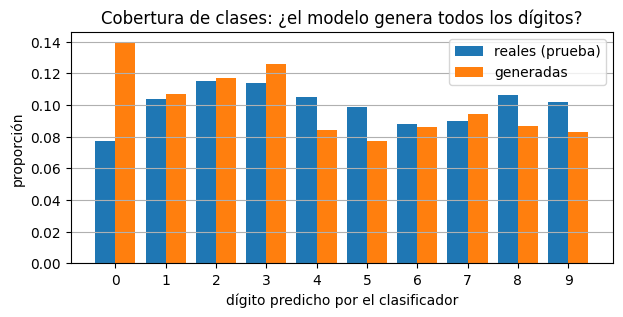

In [17]:
pred_gen, hist_gen, _, _, _ = class_stats(p_gen)
_, hist_real, _, _, _ = class_stats(p_test)

plt.figure(figsize=(7, 3))
w = 0.4
plt.bar(np.arange(10) - w / 2, hist_real, w, label="reales (prueba)")
plt.bar(np.arange(10) + w / 2, hist_gen, w, label="generadas")
plt.xticks(range(10)); plt.xlabel("dígito predicho por el clasificador"); plt.ylabel("proporción")
plt.title("Cobertura de clases: ¿el modelo genera todos los dígitos?")
plt.legend(); plt.grid(axis="y"); plt.show()

### 6.4 Inspección cualitativa guiada por las métricas
Ordenamos las imágenes generadas por la confianza del clasificador: arriba las más “legibles”, abajo las más ambiguas. Esto ayuda a entender qué tipo de errores comete el modelo.

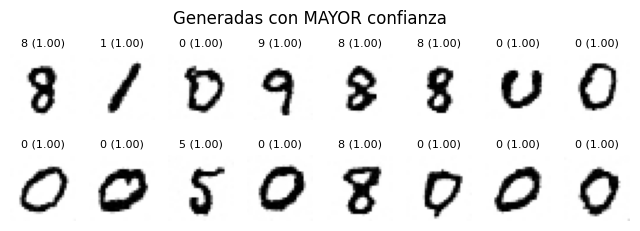

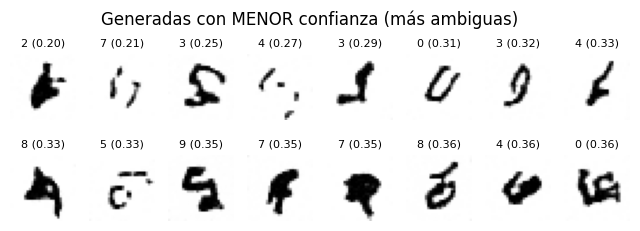

In [18]:
conf_gen = p_gen.max(1)
best = np.argsort(-conf_gen)[:16]
worst = np.argsort(conf_gen)[:16]

plot_multiple_images(X_gen[best], 8, titles=[f"{pred_gen[i]} ({conf_gen[i]:.2f})" for i in best])
plt.suptitle("Generadas con MAYOR confianza", y=1.03); plt.show()

plot_multiple_images(X_gen[worst], 8, titles=[f"{pred_gen[i]} ({conf_gen[i]:.2f})" for i in worst])
plt.suptitle("Generadas con MENOR confianza (más ambiguas)", y=1.03); plt.show()

### 6.5 ¿El modelo memoriza? Vecino más cercano en el conjunto de entrenamiento
Un buen generador produce dígitos *nuevos*, no copias. Para algunas imágenes generadas buscamos la imagen de entrenamiento más parecida en el espacio de características; si fueran idénticas, el modelo estaría memorizando.

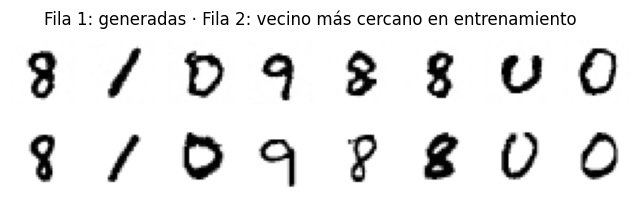

In [19]:
sub_idx = np.random.default_rng(1).choice(len(X_train), min(20000, len(X_train)), replace=False)
f_bank = feature_extractor.predict(to_pm1(X_train[sub_idx]), batch_size=1000, verbose=0)
query = best[:8]
d = ((f_gen[query][:, None, :] - f_bank[None]) ** 2).sum(-1)
nn = sub_idx[d.argmin(1)]

pairs = np.concatenate([X_gen[query], to_pm1(X_train[nn])])
plot_multiple_images(pairs, 8)
plt.suptitle("Fila 1: generadas · Fila 2: vecino más cercano en entrenamiento", y=1.02)
plt.show()

### 6.6 Análisis de los resultados

El modelo se entrenó 20 épocas y terminó con una pérdida de validación de 0,0227, prácticamente igual a la de entrenamiento: no hubo sobreajuste. El clasificador que usamos como "juez" alcanzó 98,9 % de exactitud en el conjunto de prueba, así que sus características son una base confiable para las métricas.

| Conjunto | FID ↓ | KID×1000 ↓ | Classifier Score ↑ | Confianza media | % con conf. > 0,9 | Entropía de clases (máx. 2,30) |
|---|---|---|---|---|---|---|
| Real (línea base) | 21,9 | 36.805 | 9,41 | 0,994 | 98,3 % | 2,298 |
| **Generadas por difusión** | **373,2** | **1.001.998** | **7,08** | **0,891** | **71,0 %** | **2,283** |
| Ruido gaussiano | 2.532,8 | 1.952.986 | 1,00 | 1,000 | 100 % | 0,000 |

**Calidad.** Las imágenes generadas quedan claramente del lado de los datos reales. Su FID (373) es casi 7 veces menor que el del ruido (2.533), aunque todavía unas 17 veces mayor que el de dos muestras reales entre sí (22). El *Classifier Score* de 7,1 sobre un máximo de 10 (los reales dan 9,4) y el 71 % de imágenes que el clasificador reconoce con más de 90 % de seguridad dicen lo mismo: la mayoría son dígitos legibles, pero una parte todavía tiene trazos incompletos, fusionados o demasiado gruesos. Los casos de menor confianza (sección 6.4) son justamente esos: un 4 o un 7 partidos, un 5 que se parece a un 3.

**Diversidad.** La entropía de clases es 2,283, muy cerca del máximo teórico de 2,303, y el histograma muestra que aparecen los diez dígitos en proporciones entre 7,7 % y 14 %. No hay *mode collapse*. Hay un leve exceso de 0 (14 %) y de 3 (12,6 %) y algo menos de 5 (7,7 %), probablemente porque las formas cerradas y redondeadas son las más fáciles de producir para un modelo pequeño (280 mil parámetros).

**Una lección sobre las métricas.** El ruido obtiene confianza media de 1,0: el clasificador asigna todas esas imágenes a una misma clase con total seguridad. Si miráramos solo la confianza, el ruido "ganaría". El *Classifier Score* de 1,0 y la entropía de 0 delatan que no hay ninguna diversidad. Por eso hay que leer varias métricas juntas. Los valores del KID son enormes porque las características del clasificador no están normalizadas; su escala no es comparable con valores publicados, pero el orden (real < generadas < ruido) coincide con el del FID.

**Memorización.** La comparación con los vecinos más cercanos (sección 6.5) muestra dígitos parecidos en estilo, pero no copias: el modelo genera ejemplos nuevos.

**Corrección del muestreo.** En una primera ejecución el proceso inverso arrancaba en t = T, donde la programación coseno tiene α ≈ 0,001 y el paso amplifica la imagen unas 32 veces. Eso producía algunos cuadros completamente negros (2 de 256) y sesgaba la distribución de clases (entropía 2,19). Al arrancar en t = T − 1, como el notebook de clase, los cuadros negros desaparecieron (0 de 256) y la cobertura de clases mejoró a 2,28.

In [20]:
# Guardamos el modelo entrenado (pesos) y una muestra de las imágenes generadas
model.save_weights("mnist_diffusion_final.weights.h5")
np.save("mnist_generated_samples.npy", X_gen[:256])
results.to_csv("mnist_metricas.csv")
print("Archivos guardados: mnist_diffusion_final.weights.h5, mnist_generated_samples.npy, mnist_metricas.csv")

Archivos guardados: mnist_diffusion_final.weights.h5, mnist_generated_samples.npy, mnist_metricas.csv
